# 2. Import Library

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device yang digunakan:", device)

PyTorch version: 2.14.1+cpu
GPU tersedia: False
Device yang digunakan: cpu


# 3. Load dan Persiapkan Dataset

In [2]:
ddata = pd.read_csv("D:/NLP/Modul-2/review_gopay_newest_sort.csv")
text_column = "content"

df = ddata.dropna(subset=[text_column]).copy()
df = df.reset_index(drop=True)

# Mengambil maksimal 5.000 ulasan agar lebih ringan
df = df.sample(
    n=min(5000, len(df)),
    random_state=42
).reset_index(drop=True)

print(f"Jumlah data: {len(df)}")
print("Nama kolom:", df.columns.tolist())
print("\nContoh ulasan:")
print(df[text_column].head())


Jumlah data: 5000
Nama kolom: ['userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at']

Contoh ulasan:
0    Sangat membantu dalam menyimpan uang Dhe bets
1                                               ok
2                                Tidak mudah ribet
3        sangat membantu untuk saya seorang driver
4                                      Apk terbaik
Name: content, dtype: str


# 4. Membangun Vocabulary

In [3]:
def build_vocab(texts, max_vocab=10000, min_freq=2):
    counter = Counter()

    for text in texts:
        tokens = str(text).lower().split()
        counter.update(tokens)

    vocab = {"<PAD>": 0, "<UNK>": 1}

    for word, count in counter.most_common():
        if count >= min_freq:
            if len(vocab) >= max_vocab:
                break

            if word not in vocab:
                vocab[word] = len(vocab)

    return vocab

vocab = build_vocab(df[text_column])

print("Ukuran vocabulary:", len(vocab))
print("Contoh vocabulary:", list(vocab.items())[:10])

Ukuran vocabulary: 1988
Contoh vocabulary: [('<PAD>', 0), ('<UNK>', 1), ('sangat', 2), ('gopay', 3), ('dan', 4), ('bagus', 5), ('di', 6), ('saya', 7), ('mantap', 8), ('aplikasi', 9)]


# 5. Encode Teks dan Label
Karena dataset tidak mempunyai label, bagian ini hanya melakukan encoding teks. Tidak ada LabelEncoder, num_classes, atau variabel y.

In [4]:
MAX_LEN = 100

def text_to_indices(text, vocab, max_len=100):
    tokens = str(text).lower().split()[:max_len]

    indices = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ]

    if len(indices) < max_len:
        indices += [0] * (max_len - len(indices))

    return indices


X = np.array([
    text_to_indices(text, vocab, MAX_LEN)
    for text in df[text_column]
])

print("Bentuk data X:", X.shape)
print("Contoh encoding:")
print(X[0])

Bentuk data X: (5000, 100)
Contoh encoding:
[   2   10   63 1011   64    1    1    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


# 6. Dataset dan DataLoader

In [5]:
class TextDataset(Dataset):
    def __init__(self, texts):
        self.texts = torch.LongTensor(texts)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


dataset = TextDataset(X)

data_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

print("Jumlah data:", len(dataset))
print("Jumlah batch:", len(data_loader))

batch = next(iter(data_loader))
print("Bentuk batch:", batch.shape)

Jumlah data: 5000
Jumlah batch: 157
Bentuk batch: torch.Size([32, 100])


# 7. Arsitektur RNN
Karena tidak ada label, model berikut menghasilkan representasi urutan teks, bukan prediksi kelas sentimen.

In [6]:
class RNNModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(RNNModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )
        self.rnn = nn.RNN(
            embed_dim, hidden_dim, batch_first=True
        )

        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.rnn(embedded)
        return output, hidden


rnn_model = RNNModel(
    len(vocab), 64, 64
).to(device)

print(rnn_model)


RNNModel(
  (embedding): Embedding(1988, 64, padding_idx=0)
  (rnn): RNN(64, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=1988, bias=True)
)


# 8. Arsitektur LSTM

In [7]:
class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )
        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3
        )

        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        output, (hidden, cell) = self.lstm(embedded)
        return output, hidden, cell


lstm_model = LSTMModel(
    len(vocab), 64, 64
).to(device)

print(lstm_model)

LSTMModel(
  (embedding): Embedding(1988, 64, padding_idx=0)
  (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.3)
  (output_layer): Linear(in_features=64, out_features=1988, bias=True)
)


# 9. Arsitektur GRU

In [8]:
class GRUModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(GRUModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )
        self.gru = nn.GRU(
            embed_dim,
            hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3
        )

        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.gru(embedded)
        return output, hidden


gru_model = GRUModel(
    len(vocab), 64, 64
).to(device)

print(gru_model)

GRUModel(
  (embedding): Embedding(1988, 64, padding_idx=0)
  (gru): GRU(64, 64, num_layers=2, batch_first=True, dropout=0.3)
  (output_layer): Linear(in_features=64, out_features=1988, bias=True)
)


# 10. Fungsi Training dan Evaluasi
Training tanpa label tidak menggunakan CrossEntropyLoss atau akurasi klasifikasi. Sebagai gantinya, kita bisa menggunakan tugas next-token prediction: model mempelajari memprediksi kata berikutnya dari urutan kata sebelumnya.

In [9]:
def train_model(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0

    for texts in loader:
        texts = texts.to(device)

        # Input adalah kata awal, target adalah kata berikutnya
        inputs = texts[:, :-1]
        targets = texts[:, 1:]

        optimizer.zero_grad()

        output = model(inputs)

        # Ambil output sequence dari masing-masing arsitektur
        if isinstance(model, RNNModel):
            sequence_output = output[0]
        elif isinstance(model, LSTMModel):
            sequence_output = output[0]
        else:
            sequence_output = output[0]

        # Proyeksi hidden state menjadi skor vocabulary
        logits = model.output_layer(sequence_output)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            targets.reshape(-1)
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

# 11. Training dan Perbandingan
Pada tahap ini, model belajar memprediksi kata selanjutnya. CrossEntropyLoss membandingkan prediksi dengan token berikutnya yang memang sudah ada dalam teks, bukan dengan label sentimen.

In [10]:
VOCAB_SIZE = len(vocab)
EMBED_DIM = 64
HIDDEN_DIM = 64
NUM_EPOCHS = 3

models = {
    "RNN": RNNModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "LSTM": LSTMModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "GRU": GRUModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device)
}

criterion = nn.CrossEntropyLoss(ignore_index=0)
results = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history = []

    for epoch in range(NUM_EPOCHS):
        avg_loss = train_model(
            model, data_loader, optimizer, criterion, device
        )
        history.append(avg_loss)
        print(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} "
            f"| Loss: {avg_loss:.4f}"
        )

    results[model_name] = history


Training RNN...
Epoch 1/3 | Loss: 6.4419
Epoch 2/3 | Loss: 5.7613
Epoch 3/3 | Loss: 5.5892

Training LSTM...
Epoch 1/3 | Loss: 6.4100
Epoch 2/3 | Loss: 5.8838
Epoch 3/3 | Loss: 5.7933

Training GRU...
Epoch 1/3 | Loss: 6.3533
Epoch 2/3 | Loss: 5.8909
Epoch 3/3 | Loss: 5.7839


# 12. Visualisasi Perbandingan

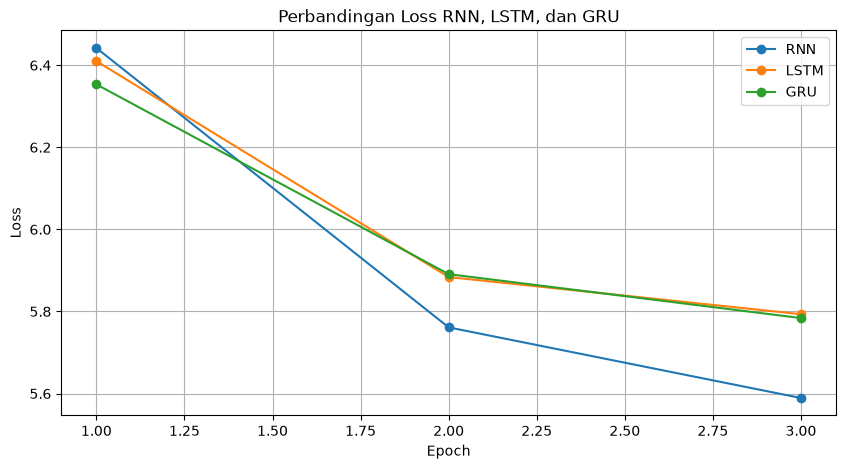

In [11]:
plt.figure(figsize=(10, 5))

for model_name, history in results.items():
    plt.plot(
        range(1, len(history) + 1),
        history,
        marker="o",
        label=model_name
    )

plt.title("Perbandingan Loss RNN, LSTM, dan GRU")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 13. Tabel Hasil Perbandingan

In [12]:
print("\nRingkasan Hasil")
print("=" * 55)
print(f"{'Model':<10} | {'Training Loss':<15} | {'Jumlah Parameter'}")
print("-" * 55)

for model_name, model in models.items():
    num_params = sum(
        p.numel() for p in model.parameters()
    )

    final_loss = results[model_name][-1]

    print(
        f"{model_name:<10} | "
        f"{final_loss:<15.4f} | "
        f"{num_params:,}"
    )


Ringkasan Hasil
Model      | Training Loss   | Jumlah Parameter
-------------------------------------------------------
RNN        | 5.5892          | 264,772
LSTM       | 5.7933          | 323,012
GRU        | 5.7839          | 306,372


# E. Tugas Analisis

In [13]:
# NOMOR 1. Menjalankan training 10–15 epoch

VOCAB_SIZE = len(vocab)
EMBED_DIM = 64
HIDDEN_DIM = 64
NUM_EPOCHS = 15

models = {
    "RNN": RNNModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "LSTM": LSTMModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "GRU": GRUModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device)
}

criterion = nn.CrossEntropyLoss(ignore_index=0)
results = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history = []

    for epoch in range(NUM_EPOCHS):
        avg_loss = train_model(
            model, data_loader, optimizer, criterion, device
        )
        history.append(avg_loss)
        print(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} "
            f"| Loss: {avg_loss:.4f}"
        )

    results[model_name] = history



Training RNN...
Epoch 1/15 | Loss: 6.3949
Epoch 2/15 | Loss: 5.8100
Epoch 3/15 | Loss: 5.6376
Epoch 4/15 | Loss: 5.4888
Epoch 5/15 | Loss: 5.3489
Epoch 6/15 | Loss: 5.2268
Epoch 7/15 | Loss: 5.1062
Epoch 8/15 | Loss: 5.0028
Epoch 9/15 | Loss: 4.8976
Epoch 10/15 | Loss: 4.7997
Epoch 11/15 | Loss: 4.7151
Epoch 12/15 | Loss: 4.6236
Epoch 13/15 | Loss: 4.5446
Epoch 14/15 | Loss: 4.4596
Epoch 15/15 | Loss: 4.3984

Training LSTM...
Epoch 1/15 | Loss: 6.4268
Epoch 2/15 | Loss: 5.9159
Epoch 3/15 | Loss: 5.8191
Epoch 4/15 | Loss: 5.7640
Epoch 5/15 | Loss: 5.7299
Epoch 6/15 | Loss: 5.6923
Epoch 7/15 | Loss: 5.6658
Epoch 8/15 | Loss: 5.6384
Epoch 9/15 | Loss: 5.5989
Epoch 10/15 | Loss: 5.5552
Epoch 11/15 | Loss: 5.5105
Epoch 12/15 | Loss: 5.4801
Epoch 13/15 | Loss: 5.4167
Epoch 14/15 | Loss: 5.3720
Epoch 15/15 | Loss: 5.3110

Training GRU...
Epoch 1/15 | Loss: 6.3469
Epoch 2/15 | Loss: 5.8609
Epoch 3/15 | Loss: 5.7401
Epoch 4/15 | Loss: 5.6870
Epoch 5/15 | Loss: 5.6148
Epoch 6/15 | Loss: 5.5379


In [14]:
# NOMOR 2, Coba ubah hidden_dim menjadi 64 dan 512

VOCAB_SIZE = len(vocab)
EMBED_DIM = 64
HIDDEN_DIM = 512
NUM_EPOCHS = 15

models = {
    "RNN": RNNModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "LSTM": LSTMModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "GRU": GRUModel(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device)
}

criterion = nn.CrossEntropyLoss(ignore_index=0)
results_512 = {}

import time

for model_name, model in models.items():
    print(f"\nTraining {model_name} dengan HIDDEN_DIM = 512...")
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history = []
    start_time = time.time()

    for epoch in range(NUM_EPOCHS):
        avg_loss = train_model(
            model, data_loader, optimizer, criterion, device
        )
        history.append(avg_loss)
        print(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} "
            f"| Loss: {avg_loss:.4f}"
        )

    elapsed_time = time.time() - start_time
    results_512[model_name] = {
        "loss": history,
        "waktu": elapsed_time
    }

    print(f"Waktu training: {elapsed_time:.2f} detik")



Training RNN dengan HIDDEN_DIM = 512...
Epoch 1/15 | Loss: 6.0895
Epoch 2/15 | Loss: 5.3798
Epoch 3/15 | Loss: 4.9171
Epoch 4/15 | Loss: 4.4595
Epoch 5/15 | Loss: 3.9995
Epoch 6/15 | Loss: 3.5689
Epoch 7/15 | Loss: 3.1577
Epoch 8/15 | Loss: 2.8127
Epoch 9/15 | Loss: 2.4903
Epoch 10/15 | Loss: 2.2082
Epoch 11/15 | Loss: 1.9665
Epoch 12/15 | Loss: 1.7472
Epoch 13/15 | Loss: 1.5619
Epoch 14/15 | Loss: 1.4169
Epoch 15/15 | Loss: 1.2644
Waktu training: 4778.04 detik

Training LSTM dengan HIDDEN_DIM = 512...
Epoch 1/15 | Loss: 6.0781
Epoch 2/15 | Loss: 5.6747
Epoch 3/15 | Loss: 5.5175
Epoch 4/15 | Loss: 5.3299
Epoch 5/15 | Loss: 5.0602
Epoch 6/15 | Loss: 4.8106
Epoch 7/15 | Loss: 4.5123
Epoch 8/15 | Loss: 4.1810
Epoch 9/15 | Loss: 3.8092
Epoch 10/15 | Loss: 3.4002
Epoch 11/15 | Loss: 2.9813
Epoch 12/15 | Loss: 2.5856
Epoch 13/15 | Loss: 2.2247
Epoch 14/15 | Loss: 1.9107
Epoch 15/15 | Loss: 1.6322
Waktu training: 35296.02 detik

Training GRU dengan HIDDEN_DIM = 512...
Epoch 1/15 | Loss: 5.99

In [17]:
# NOMOR 3, Menambahkan bidirectional=True pada LSTM

class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(
            hidden_dim * 2, vocab_size
        )

    def forward(self, x):
        embedded = self.embedding(x)
        output, _ = self.lstm(embedded)
        output = self.fc(output)
        return output

In [18]:
# NOMOR 4,tabel perbandingan RNN, LSTM, GRU berdasarkan akurasi, loss, dan jumlah parameter.

import pandas as pd

hasil_perbandingan = []

for nama_model, model in models.items():
    jumlah_parameter = sum(
        p.numel() for p in model.parameters()
    )

    loss_akhir = results[nama_model][-1]

    hasil_perbandingan.append({
        "Model": nama_model,
        "Training Loss": round(loss_akhir, 4),
        "Jumlah Parameter": jumlah_parameter
    })

tabel_perbandingan = pd.DataFrame(hasil_perbandingan)

print("Tabel Perbandingan RNN, LSTM, dan GRU")
display(tabel_perbandingan)

Tabel Perbandingan RNN, LSTM, dan GRU


,Model,Training Loss,Jumlah Parameter
0,RNN,4.3984,1443012
1,LSTM,5.3110,4432068
2,GRU,4.9208,3610820


**NOMOR 5: Pada kalimat panjang (>50 kata), model mana yang lebih baik menangkap konteks?**

Model LSTM lebih cocok untuk menangkap konteks teks yang panjang, termasuk teks lebih dari 50 kata, karena memiliki mekanisme *memory cell* dan *gate* yang membantu menyimpan informasi penting serta mengurangi masalah hilangnya informasi ketika memproses urutan yang panjang. GRU juga mampu menangkap konteks panjang dengan mekanisme yang lebih sederhana, sedangkan RNN biasa lebih rentan mengalami masalah *vanishing gradient*. Namun, hasil sebenarnya tetap bergantung pada data dan proses pelatihan yang digunakan.